**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 1, notebook 1 of 2

| | |
|---|---|
| **Goal** | Know the attributes of PATSTAT you need to define your sector (Step 0) and describe it (Step 1): what each one means, how it is coded, and where it can mislead you. |
| **Before this** | Tutorial 0 (TIP platform, PATSTAT basics, Step 1 general description) |
| **Time** | 30 min |
| **PATSTAT environment** | TEST (switch to PROD for final numbers) |

← [Tutorial 0 · Step 1 of the PW: general description of the sector](../tutorial_0/02_step1_general_description.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)

<sub>Adapted from the EPO TIP training materials (https://github.com/epo/tip-training). This version has been modified and is not authorised by the EPO; the EPO is not responsible for its correctness.</sub>

### APPUNTI 

first kind of actors are inventors. the second kind are applicants.
the problem is that in TLS201 the key is the code of filing.
solution? TSL207 which provides a match between the code of filing application and the code of the person. 

in TSL201 we also have IPR type. why? they not only involve patents but also utility models which are like patents but less novel. 
so if you want to set only one patent you need to select, will see later.


# Patent attributes

In Tutorial 0 we queried PATSTAT and built a first sector dataset. Here we slow down and look at the **attributes** we used, one table at a time. Each attribute comes with a short definition, a query that shows what it looks like, and the pitfalls to keep in mind when you use it in your project work (PW).

We cover six tables. Titles and abstracts are the only text fields we consider; all the others are codes, dates, counts and identifiers.

| Table | What one row is | Attributes we look at |
|---|---|---|
| `TLS201_APPLN` | one patent application | identifiers, authority, kind and IPR type, dates, PCT route, grant, families, family size, citations, number of applicants and inventors |
| `TLS224_APPLN_CPC` | one CPC symbol assigned to one application | `cpc_class_symbol` |
| `TLS202_APPLN_TITLE` | the title of one application | `appln_title_lg`, `appln_title` |
| `TLS203_APPLN_ABSTR` | the abstract of one application | `appln_abstract_lg`, `appln_abstract` |
| `TLS207_PERS_APPLN` | one link between a person and an application | `applt_seq_nr`, `invt_seq_nr` |
| `TLS206_PERSON` | one applicant or inventor, as written in a filing | names and their standardised versions, country, sector, NUTS region, HAN |

**Which attribute for which PW step**

| PW step | Question | Attributes |
|---|---|---|
| Step 0 · Define the sector | Which patents belong to my technology? | `cpc_class_symbol`, `appln_title`, `appln_abstract`, `appln_kind`, `ipr_type` |
| Step 1 · General description | How big is the sector and is it growing? | `earliest_filing_year`, `appln_filing_year`, `docdb_family_id` |
| | Which technologies make it up? | `cpc_class_symbol` |
| | Where is it happening? | `appln_auth`, `receiving_office`, `person_ctry_code` (via `TLS207`) |
| | Which patents matter more? | `granted`, `docdb_family_size`, `nb_citing_docdb_fam` |
| | Who is patenting? | `psn_name`, `han_name`, `psn_sector`, `applt_seq_nr`, `invt_seq_nr` |

Along the way you will find some **Your turn** questions. They ask which tables you need to answer a question, and in which order to join them (the *chain of tables*). Try to answer before you open the solution.

## Contents

1. Setup
2. How the six tables are connected
3. `TLS201_APPLN`: the application
4. `TLS224_APPLN_CPC`: the CPC classification
5. `TLS202_APPLN_TITLE` and `TLS203_APPLN_ABSTR`: title and abstract
6. `TLS207_PERS_APPLN`: who did what on which application
7. `TLS206_PERSON`: applicants and inventors
8. Your turn: which tables, and in which order?
8. Checklist for Step 0 and Step 1

## 1. Setup

All imports in one cell. The queries below run on the **TEST** environment, a small sample of PATSTAT: the numbers you get are fine for learning, not for your final slides.

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import case, func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,          # applications
    TLS202_APPLN_TITLE,    # titles
    TLS203_APPLN_ABSTR,    # abstracts
    TLS206_PERSON,         # persons (applicants and inventors)
    TLS207_PERS_APPLN,     # person <-> application links
    TLS224_APPLN_CPC,      # CPC classification
)

# Connect to PATSTAT and open an ORM session
patstat = PatstatClient(env="TEST")
db = patstat.orm()

pd.set_option("display.max_colwidth", 80)

## 2. How the six tables are connected

`TLS201_APPLN` is the centre. Every other table has an `appln_id` column that points to it, except `TLS206_PERSON`, which is reached through the bridge table `TLS207_PERS_APPLN`.

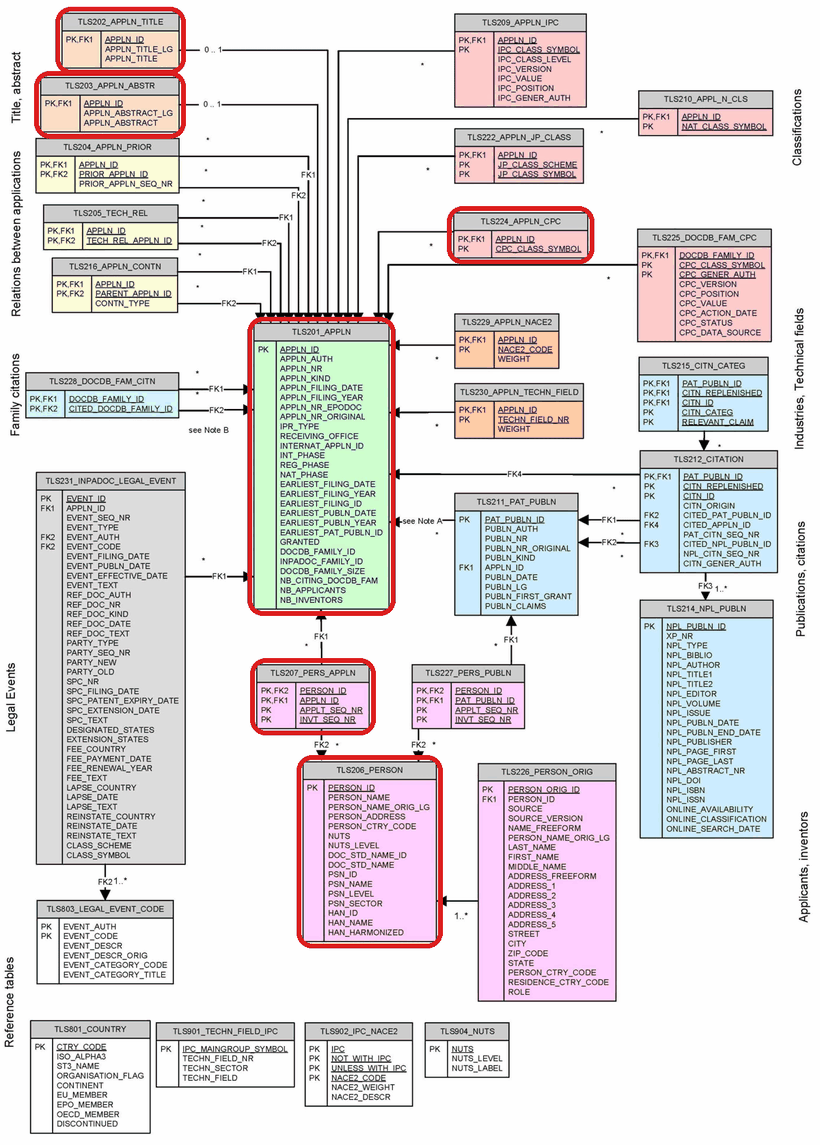

*The PATSTAT Global schema: the six tables of this notebook are circled in red.*

```
TLS224_APPLN_CPC ──┐
TLS202_APPLN_TITLE ─┼── appln_id ── TLS201_APPLN ── appln_id ── TLS207_PERS_APPLN ── person_id ── TLS206_PERSON
TLS203_APPLN_ABSTR ─┘
```

- `TLS201` → `TLS202` and `TLS201` → `TLS203`: **one to one** (at most one title and one abstract per application).
- `TLS201` → `TLS224`: **one to many** (an application has several CPC symbols).
- `TLS201` ↔ `TLS206`: **many to many** (an application has several persons, a person has several applications). `TLS207` stores each pair.

## 3. `TLS201_APPLN`: the application

One row per patent application, at any patent office in the world. This is the table you will use most: almost every indicator of Step 1 starts here.

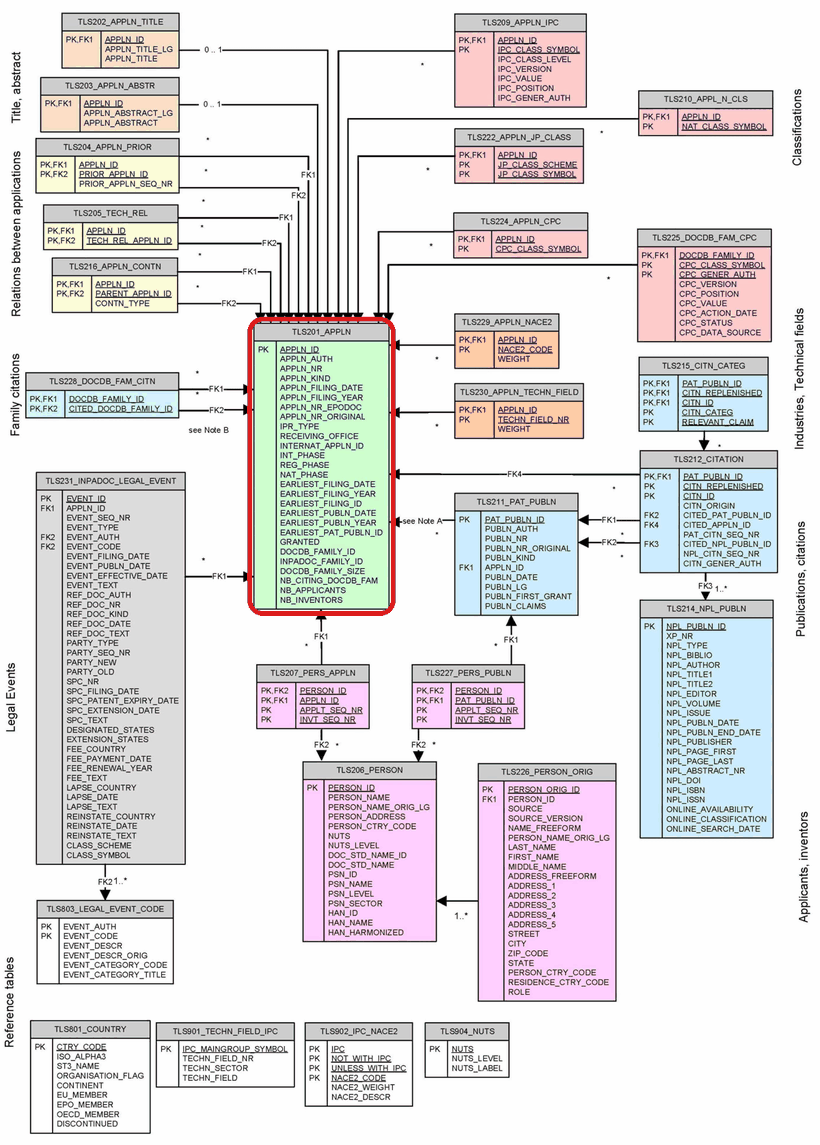

*Where TLS201_APPLN sits in the PATSTAT schema: at the centre, every other table points to it.*

### 3.1 Identifiers: `appln_id`, `appln_nr`, `appln_nr_epodoc`

| Attribute | Meaning |
|---|---|
| `appln_id` | Technical key created by PATSTAT. Use it for joins, never for interpretation. Values of 0 and above 900 000 000 are **dummy** applications created to keep the database consistent (for example, a priority that is cited but not in the data). |
| `appln_auth` + `appln_nr` | The application number given by the patent office. It is unique only together with the authority: two offices can use the same number. |
| `appln_nr_epodoc` | The same number in the EPODOC format (authority + year + number). It is the one to use when you look an application up in Espacenet. |
| `appln_nr_original` | The number as written by the office. Often missing. **Not to be used** |

Let's look at a few EP applications.

### APPUNTI

appln_auth is the code of the patent office in which the application was first filed. i.e. EPO

we can look the number of filing s in a certain office to get ad idea of ?.

In [15]:
q = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_nr,
        TLS201_APPLN.appln_nr_epodoc,
        TLS201_APPLN.appln_nr_original,
    )
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.appln_id < 900000000)   # exclude dummy applications
    .limit(10)
)

patstat.df(q)

,appln_id,appln_auth,appln_nr,appln_nr_epodoc,appln_nr_original
0,16427397,EP,78100340,None,78100340
1,16427726,EP,78100696,None,78100696
2,16430987,EP,79100243,None,79100243
3,16431185,EP,79100454,None,79100454
4,16431627,EP,79100919,None,79100919
5,16432013,EP,79101325,None,79101325
6,16432859,EP,79102216,None,79102216
7,16434050,EP,79103458,None,79103458
8,16434245,EP,79103661,None,79103661
9,16434392,EP,79103812,None,79103812


The same invention appears with different `appln_id` values at different offices, so a count of `appln_id` is a count of **applications**, not of inventions. We come back to this with families.

How many dummy applications are there? Count them once, and remember to filter them out of every indicator.

In [16]:
q = db.query(
    func.count(TLS201_APPLN.appln_id).label("all_applications"),
    func.sum(case((TLS201_APPLN.appln_id > 900000000, 1), else_=0)).label("dummy_applications"),
)

patstat.df(q)

,all_applications,dummy_applications
0,323708,668


### 3.2 `appln_auth`: where the application was filed

`appln_auth` is the **patent office** (authority) that received the application: a national office (`US`, `CN`, `JP`, `DE`, `IT`...), a regional one (`EP` for the European Patent Office) or `WO` for an international application under the PCT.

It answers "where do applicants seek protection?", not "where does the invention come from?". For the second question we will use the country of applicants and inventors.

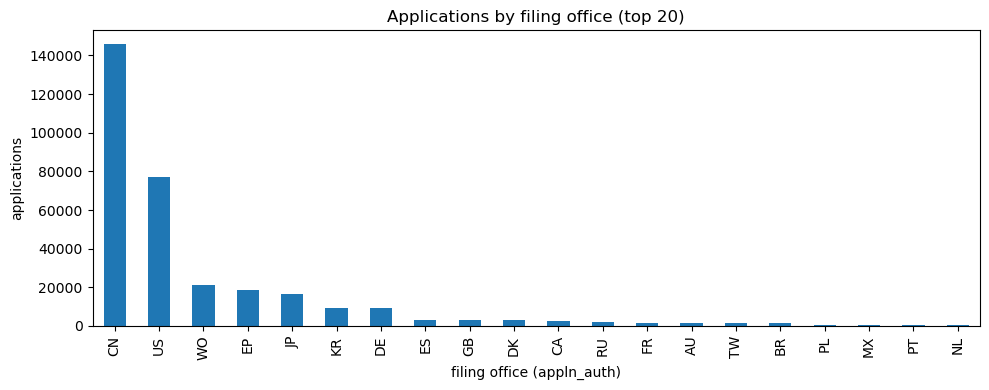

In [17]:
q = (
    db.query(
        TLS201_APPLN.appln_auth,
        func.count(TLS201_APPLN.appln_id).label("applications"),
    )
    .filter(TLS201_APPLN.appln_id < 900000000)
    .group_by(TLS201_APPLN.appln_auth)
    .order_by(func.count(TLS201_APPLN.appln_id).desc())
    .limit(20)
)

by_auth = patstat.df(q)

# Bar chart of the 20 offices with most applications
ax = by_auth.plot.bar(x="appln_auth", y="applications", legend=False, figsize=(10, 4))
ax.set_xlabel("filing office (appln_auth)")
ax.set_ylabel("applications")
ax.set_title("Applications by filing office (top 20)")
plt.tight_layout()
plt.show()

The chart counts applications per office. A large office (CN, US, JP) dominates simply because of its size and its filing habits, for example many utility models in China. When you compare offices in Step 1, look at shares and growth, not only at levels.

### 3.3 `appln_kind` and `ipr_type`: what kind of right

`appln_kind` is a code of up to **two characters** that tells the type of application. The main values are:

| `appln_kind` | Meaning |
|---|---|
| `A` | patent application |
| `U` | utility model |
| `W` | international (PCT) application |
| `D2`, `F`, `T`... | other or office-specific kinds (divisionals, designs, translations...) |

`ipr_type` groups them into three intellectual property rights:

| `ipr_type` | Meaning |
|---|---|
| `PI` | patent of invention |
| `UM` | utility model |
| `DM` | design |

Utility models protect "small" inventions, with a shorter life and usually no substantive examination. They are very common in China, Japan, Korea, Germany. Designs protect the appearance of a product, not a technical solution, so they are normally excluded from a technology study.

In [18]:
q = (
    db.query(
        TLS201_APPLN.ipr_type,
        TLS201_APPLN.appln_kind,
        func.count(TLS201_APPLN.appln_id).label("applications"),
    )
    .filter(TLS201_APPLN.appln_id < 900000000)
    .group_by(TLS201_APPLN.ipr_type, TLS201_APPLN.appln_kind)
    .order_by(func.count(TLS201_APPLN.appln_id).desc())
    .limit(15)
)

patstat.df(q)

,ipr_type,appln_kind,applications
0,PI,A,244565
1,UM,U,50309
2,PI,W,20937
3,PI,T,6494
4,DP,F,614
5,PI,D,96
6,UM,A,16
7,PI,E,8
8,PI,K,1


### APPUNTI

to get overview of patents we can look at the top 5 offices in the world.
we look at the earliest filing date of the family of patent application. we can also use just the earliest year.

we cannot use years up to 2025 since patents take a couple of years to appear here. so use only patents up to 2022 (2023 if the sector of the patent is new, otherwise stick to 2022).



In [19]:
IP5 = ["CN", "EP", "JP", "KR", "US"]

q = (
    db.query(
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.ipr_type,
        func.count(TLS201_APPLN.appln_id).label("applications"),
    )
    .filter(TLS201_APPLN.appln_auth.in_(IP5))
    .filter(TLS201_APPLN.appln_id < 900000000)
    .group_by(TLS201_APPLN.appln_auth, TLS201_APPLN.ipr_type)
)

ipr = patstat.df(q)

# One row per office, one column per IPR type, values as shares of the office total
ipr_share = ipr.pivot(index="appln_auth", columns="ipr_type", values="applications").fillna(0)
ipr_share = ipr_share.div(ipr_share.sum(axis=1), axis=0).round(3)
ipr_share

ipr_type,DP,PI,UM
appln_auth,,,
CN,0.000,0.679,0.321
EP,0.000,1.000,0.000
JP,0.000,0.957,0.043
KR,0.000,0.962,0.038
US,0.008,0.992,0.000


Each row sums to 1: it is the mix of rights requested at that office. Offices where the `UM` share is large will look much bigger than the others if you do not filter by `ipr_type`.

### 3.4 Dates: filing, priority, publication

| Attribute | Meaning |
|---|---|
| `appln_filing_date`, `appln_filing_year` | The date on which **this** application was filed at this office. Missing dates are coded as `9999-12-31` (year `9999`). |
| `earliest_filing_date`, `earliest_filing_year` | The earliest filing date in the **DOCDB family** of the application: the **priority date**. It is the same for all applications of the family, and it is the date closest to the moment of invention. |
| `earliest_filing_id` | The `appln_id` of that earliest application. |
| `earliest_publn_date`, `earliest_publn_year` | The first publication of the application. Patent applications are published about **18 months** after the priority date. |
| `earliest_pat_publn_id` | The first publication that is a granted patent (0 if none). |

**For Step 1:** use `earliest_filing_year` to measure when inventions were made, and count families (section 3.6). Use `appln_filing_year` when you look at what happens at each office.

Let's compare the two years on EP applications.

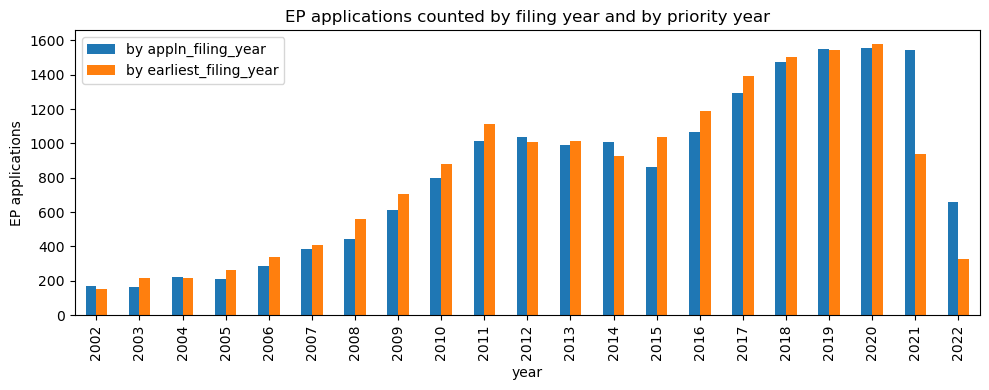

In [20]:
q = (
    db.query(
        TLS201_APPLN.appln_filing_year,
        func.count(TLS201_APPLN.appln_id).label("applications"),
    )
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.appln_filing_year.between(2002, 2022))
    .group_by(TLS201_APPLN.appln_filing_year)
)
by_filing = patstat.df(q).set_index("appln_filing_year")

q = (
    db.query(
        TLS201_APPLN.earliest_filing_year,
        func.count(TLS201_APPLN.appln_id).label("applications"),
    )
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.earliest_filing_year.between(2002, 2022))
    .group_by(TLS201_APPLN.earliest_filing_year)
)
by_priority = patstat.df(q).set_index("earliest_filing_year")

# Put the two counts side by side, one row per year
years = pd.DataFrame({
    "by appln_filing_year": by_filing["applications"],
    "by earliest_filing_year": by_priority["applications"],
}).sort_index()

ax = years.plot.bar(figsize=(10, 4))
ax.set_xlabel("year")
ax.set_ylabel("EP applications")
ax.set_title("EP applications counted by filing year and by priority year")
plt.tight_layout()
plt.show()

The two series count the same EP applications but place them in different years. The priority year comes first: many EP applications claim the priority of an earlier national filing, about one year before. Both series drop in the last years, because recent applications are not yet published (18 months) or not yet loaded in PATSTAT. This **truncation** is not a decline of the sector: stop your time series at the last complete year, and say which one it is.

Missing dates are coded with year 9999. Check how many there are before you group by year.

In [21]:
q = (
    db.query(func.count(TLS201_APPLN.appln_id).label("applications_with_missing_filing_year"))
    .filter(TLS201_APPLN.appln_filing_year == 9999)
)

patstat.df(q)

,applications_with_missing_filing_year
0,964


### APPUNTI

inside tls201 to look at family we look at docdb family id. 
it's important to look at family count and not single filing since I can have multiple filings for a single patent.

then we can use docdb family size to count how many offices are related to a single family. why is it so important for us?
obv an invention filed in multiple offices has more value since more money was invested.


### 3.6 Families: `docdb_family_id` and `inpadoc_family_id`

The same invention is usually filed at several offices. A **patent family** groups these applications.

| Attribute | Meaning |
|---|---|
| `docdb_family_id` | **DOCDB simple family**: applications that claim exactly the same priorities. Every application belongs to exactly one DOCDB family. This is the family we use to count **inventions**. <--- **to be used in the PW** |
| `inpadoc_family_id` | **INPADOC extended family**: applications linked directly or indirectly by at least one shared priority. Larger, it can merge related but different inventions. |

Count both on the same data to see the difference.

In [22]:
q = (
    db.query(
        func.count(TLS201_APPLN.appln_id).label("applications"),
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("docdb_families"),
        func.count(TLS201_APPLN.inpadoc_family_id.distinct()).label("inpadoc_families"),
    )
    .filter(TLS201_APPLN.earliest_filing_year.between(2015, 2020))
    .filter(TLS201_APPLN.appln_id < 900000000)
)

patstat.df(q)

,applications,docdb_families,inpadoc_families
0,134635,103334,102157


There are fewer DOCDB families than applications, and fewer INPADOC families than DOCDB families. Counting `appln_id` counts the same invention once per office; counting distinct `docdb_family_id` counts it once.

**For Step 1:** measure the size and growth of your sector in **DOCDB families by earliest filing year**. Use applications only when the question is about offices.

### 3.7 `docdb_family_size`: how many offices

`docdb_family_size` is the number of applications in the DOCDB family. Filing at more offices costs more, so a large family suggests the applicant expects the invention to be **commercially valuable** in several markets. It is one of the most used value indicators.

In [23]:
# One row per family (any application of the family carries the same size)
q = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        func.max(TLS201_APPLN.docdb_family_size).label("docdb_family_size"),
    )
    .filter(TLS201_APPLN.earliest_filing_year.between(2015, 2020))
    .filter(TLS201_APPLN.appln_id < 900000000)
    .group_by(TLS201_APPLN.docdb_family_id)
)

fam = patstat.df(q)

fam["docdb_family_size"].describe()

count    103334.000000
mean          1.701879
std           2.136253
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         107.000000
Name: docdb_family_size, dtype: float64

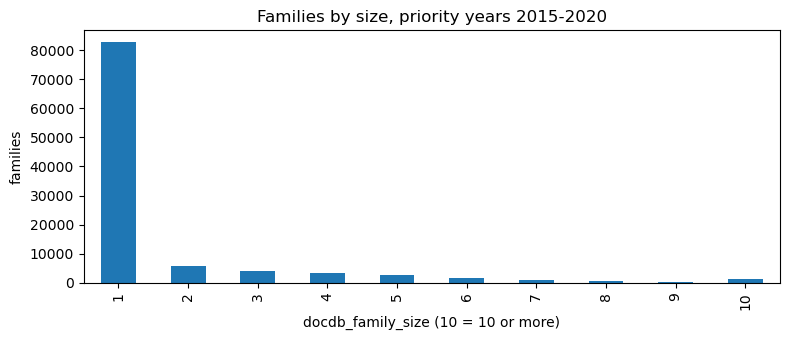

In [24]:
# Distribution of family size, capped at 10 for readability
sizes = fam["docdb_family_size"].clip(upper=10).value_counts().sort_index()

ax = sizes.plot.bar(figsize=(8, 3.5))
ax.set_xlabel("docdb_family_size (10 = 10 or more)")
ax.set_ylabel("families")
ax.set_title("Families by size, priority years 2015-2020")
plt.tight_layout()
plt.show()

### APPUNTI

antoher index of quality of patent is: GRANTED
not guaranteed that the patent gets accepted. even if I pay. which means that a company is good at innovation if the share of patent filings taht are subitted are accepted. this is stored in the attribute 'granted', in tls201. 

Most families have one or two applications: the invention was filed at a single office, or at one office plus a PCT application. A small number of families are very large.

### 3.8 `granted`

`granted` is `Y` if the application has been granted, `N` otherwise. `N` does not mean "refused": the application may still be under examination, withdrawn, or refused.

In [25]:
q = (
    db.query(
        TLS201_APPLN.appln_auth,
        func.count(TLS201_APPLN.appln_id).label("applications"),
        func.sum(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("granted"),
    )
    .filter(TLS201_APPLN.appln_auth.in_(IP5))
    .filter(TLS201_APPLN.ipr_type == "PI")
    .filter(TLS201_APPLN.appln_filing_year.between(2010, 2015))
    .group_by(TLS201_APPLN.appln_auth)
)

grants = patstat.df(q)
grants["grant_rate"] = (grants["granted"] / grants["applications"]).round(3)
grants.sort_values("grant_rate", ascending=False)

,appln_auth,applications,granted,grant_rate
0,US,21526,16547,0.769
4,KR,3499,2556,0.730
2,EP,5711,4044,0.708
3,CN,18852,12174,0.646
1,JP,3685,2369,0.643


The grant rate is the share of applications filed in 2010–2015 that are granted today. We take older filing years on purpose: examination takes several years, so recent applications have not had time to be granted.

Read it together with the volume of each office. Offices differ in examination standards, in fees, and in what applicants file there, so a higher grant rate does not mean better inventions. Within one office, a sector with a grant rate far from the office average is worth a comment.

### APPUNTI

another index is the citation amount. per forza se una patente ha tante citazioni vuol dire che è molto importante. sotto vediamo come ottenere questa info


### 3.9 `nb_citing_docdb_fam`: forward citations

`nb_citing_docdb_fam` is the number of DOCDB families that cite this application (or another application of its family). It is the most used proxy of **technological importance**: an invention cited by many later inventions has been built upon.

Two cautions:
- Citations take years to arrive, so recent families always have few. Compare families of the same priority year.
- The distribution is **very skewed**: most families get no citation, a few get many. Look at the median and at the share of families with at least one citation, not only at the mean.

A toy example shows why the mean misleads:

In [26]:
# Six imaginary families and their forward citations
toy = pd.Series([0, 0, 0, 1, 2, 40], name="nb_citing_docdb_fam")

print("mean:  ", toy.mean())
print("median:", toy.median())

mean:   7.166666666666667
median: 0.5


One family with 40 citations pulls the mean to 7.2, while the typical family has fewer than one citation (median 0.5). Now the real data:

In [27]:
q = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.earliest_filing_year,
        func.max(TLS201_APPLN.nb_citing_docdb_fam).label("nb_citing_docdb_fam"),
    )
    .filter(TLS201_APPLN.earliest_filing_year.between(2010, 2015))
    .filter(TLS201_APPLN.appln_id < 900000000)
    .group_by(TLS201_APPLN.docdb_family_id, TLS201_APPLN.earliest_filing_year)
)

cit = patstat.df(q)

# For each priority year: mean, median and share of families cited at least once
summary = cit.groupby("earliest_filing_year")["nb_citing_docdb_fam"].agg(
    mean="mean",
    median="median",
    share_cited=lambda s: (s > 0).mean(),
).round(2)
summary

,mean,median,share_cited
earliest_filing_year,,,
2010,19.68,9.0,0.99
2011,17.33,8.0,0.99
2012,15.91,7.0,0.99
2013,14.63,7.0,0.99
2014,13.60,6.0,0.99
2015,11.26,5.0,0.98


For each priority year, the table gives the mean, the median, and the share of families with at least one forward citation. The mean is well above the median, as in the toy example, and all three tend to fall for the most recent years, which have had less time to be cited.

### 3.10 `nb_applicants` and `nb_inventors`

The number of applicants and of inventors of the application. They are counted only for persons whose name is available in Latin characters: an application whose names are only in Chinese or Japanese script can show **0**. We will count persons more reliably from `TLS207`.

In [28]:
q = (
    db.query(
        TLS201_APPLN.appln_auth,
        func.count(TLS201_APPLN.appln_id).label("applications"),
        func.sum(case((TLS201_APPLN.nb_applicants == 0, 1), else_=0)).label("zero_applicants"),
        func.avg(TLS201_APPLN.nb_inventors).label("avg_inventors"),
    )
    .filter(TLS201_APPLN.appln_auth.in_(IP5))
    .filter(TLS201_APPLN.appln_filing_year.between(2015, 2020))
    .group_by(TLS201_APPLN.appln_auth)
)

team = patstat.df(q)
team["share_zero_applicants"] = (team["zero_applicants"] / team["applications"]).round(3)
team

,appln_auth,applications,zero_applicants,avg_inventors,share_zero_applicants
0,US,20664,33,2.805507,0.002
1,JP,3624,858,1.895971,0.237
2,EP,7803,3,2.572857,0.000
3,CN,78212,47,4.096034,0.001
4,KR,3629,76,2.228162,0.021


The share of applications with 0 applicants tells you where the counts cannot be trusted. Where it is high, an average number of inventors per application is biased downward.

**For Step 1:** the number of inventors is a rough proxy of the size of the research team; more applicants on one application signals collaboration (co-applications).

### Your turn 1 · How many patents were filed in China?

**Question:** how many patent applications, and how many families, were filed at the Chinese patent office in 2015?

Before you look at the solution, answer two questions:
1. Which tables do you need?
2. In which order do you join them (the chain of tables)?

<details>
<summary><b>Solution</b> (click to open)</summary>

"Filed in China" means **filed at the Chinese office**: `appln_auth = 'CN'`. Everything we need is in **one table**:

**TLS201_APPLN**: `appln_auth` for the office, `appln_filing_year` for the year, `appln_id` to count applications, `docdb_family_id` to count families. No join is needed.

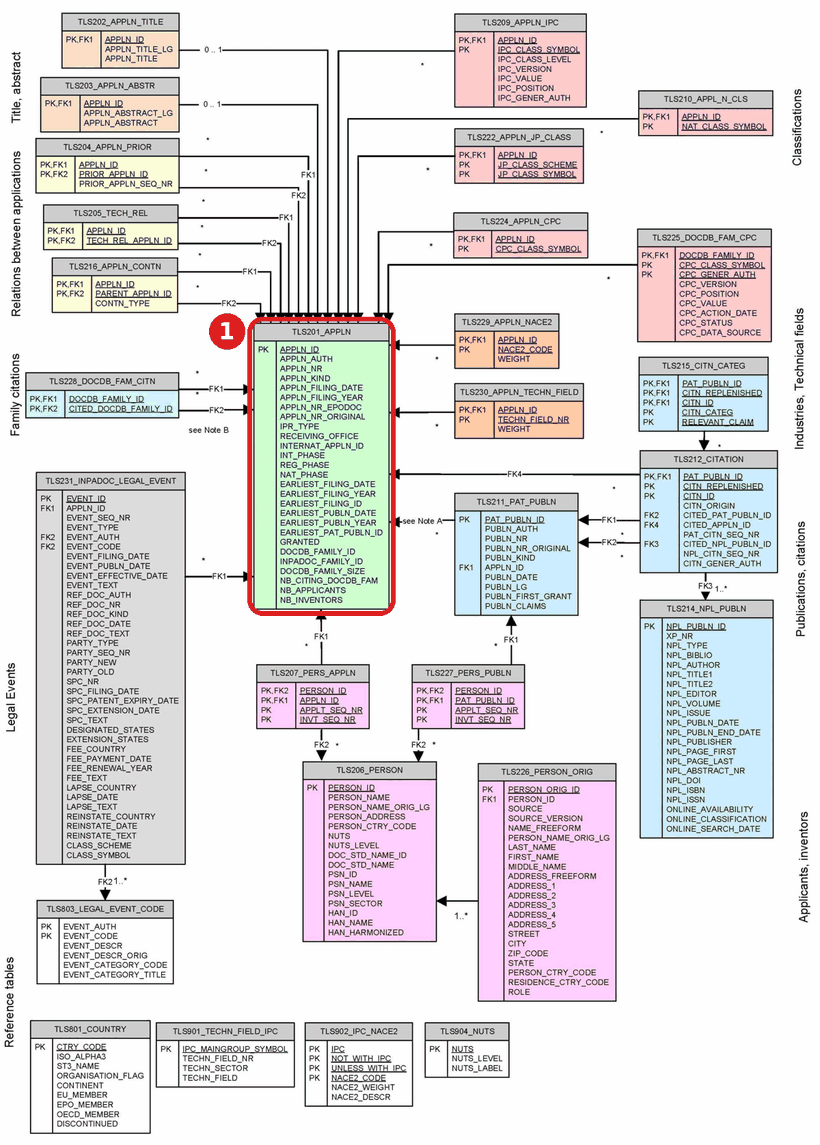

Keep `ipr_type` in mind: at the Chinese office many filings are utility models (`UM`), not patents (`PI`).
</details>

In [29]:
# Your turn 1: applications and families filed at the Chinese office in 2015, by type of right
q = (
    db.query(
        TLS201_APPLN.ipr_type,
        func.count(TLS201_APPLN.appln_id).label("applications"),
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families"),
    )
    .filter(TLS201_APPLN.appln_auth == "CN")          # filed at the Chinese office
    .filter(TLS201_APPLN.appln_filing_year == 2015)   # in 2015
    .filter(TLS201_APPLN.appln_id < 900000000)        # no dummy applications
    .group_by(TLS201_APPLN.ipr_type)
)

patstat.df(q)

,ipr_type,applications,families
0,PI,4274,4240
1,UM,2015,2015


Count the patents (`PI`) and the utility models (`UM`) separately: if you add them up, China looks much larger than if you count patents only. We come back to "China" in Your turn 3, where it means something different.

## 4. `TLS224_APPLN_CPC`: the CPC classification

The **Cooperative Patent Classification (CPC)** describes the technical content of an application with a hierarchy of codes, for example:

| Level | Example | Meaning |
|---|---|---|
| Section | `H` | Electricity |
| Class | `H01` | Electric elements |
| Subclass | `H01M` | Batteries, fuel cells |
| Main group | `H01M 8/00` | Fuel cells |
| Subgroup | `H01M 8/04` | Auxiliary arrangements of fuel cells |

The `Y` section is special: it tags cross-cutting topics, for example `Y02E` for technologies that mitigate climate change in energy.

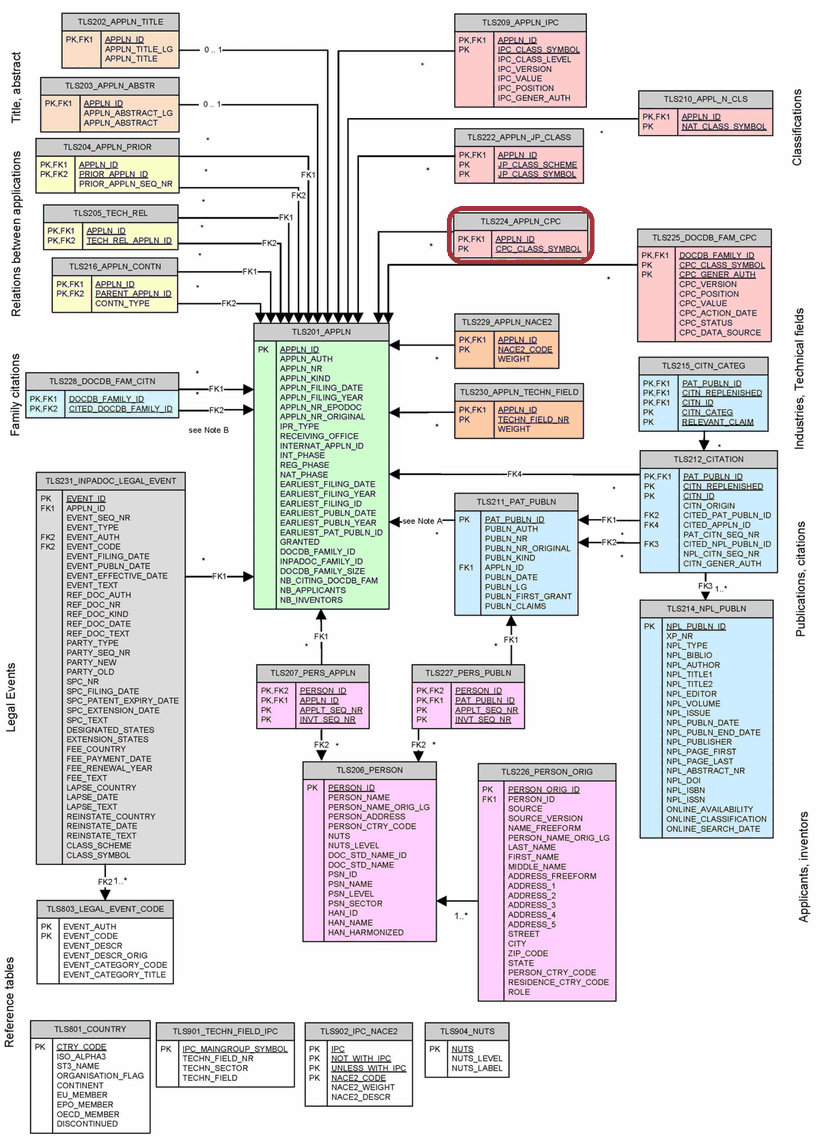

*TLS224_APPLN_CPC in the PATSTAT schema: linked to TLS201 through appln_id.*

`TLS224_APPLN_CPC` has one row per application and CPC symbol, so an application appears as many times as it has symbols.

### 4.1 The format of `cpc_class_symbol`

The symbol is a string of up to 19 characters, **padded with blanks** so that the main group always takes the same position: `H02S  40/30`, `H01M   8/04`. A filter like `== "H01M 8/04"` finds nothing. Let's look at some symbols, with their length.

In [30]:
q = (
    db.query(
        TLS224_APPLN_CPC.appln_id,
        TLS224_APPLN_CPC.cpc_class_symbol,
        func.length(TLS224_APPLN_CPC.cpc_class_symbol).label("length"),
        func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("symbol_without_blanks"),
    )
    .limit(10)
)

patstat.df(q)

,appln_id,cpc_class_symbol,length,symbol_without_blanks
0,56834056,B60R 13/005,12,B60R13/005
1,56834056,G01S 7/027,12,G01S7/027
2,56834056,G01S 7/03,11,G01S7/03
3,56834056,G01S 13/0209,13,G01S13/0209
4,56834056,G01S 13/931,12,G01S13/931
5,56834056,G01S2013/93271,14,G01S2013/93271
6,56834056,H01Q 1/3233,13,H01Q1/3233
7,56834056,H01Q 1/44,11,H01Q1/44
8,56834056,H01Q 13/02,11,H01Q13/02
9,56834056,H01Q 19/08,11,H01Q19/08


The third column is the symbol with the blanks removed. Two safe ways to select a technology:

1. **Prefix on the subclass**, which never contains blanks: `cpc_class_symbol.like("H01M%")`.
2. **Remove the blanks, then match**: `func.replace(cpc_class_symbol, " ", "").like("H01M8/%")`.

The next query uses the second way to select the fuel-cell main group `H01M 8/` and counts applications and families by filing office.

In [31]:
CPC_PREFIX = "H01M8/"   # fuel cells; write the prefix without blanks

symbol_no_blanks = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")

q = (
    db.query(
        TLS201_APPLN.appln_auth,
        func.count(TLS201_APPLN.appln_id.distinct()).label("applications"),
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families"),
    )
    .select_from(TLS224_APPLN_CPC)                        # start from the CPC table...
    .join(TLS201_APPLN, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)   # ...and add the applications
    .filter(symbol_no_blanks.like(CPC_PREFIX + "%"))
    .group_by(TLS201_APPLN.appln_auth)
    .order_by(func.count(TLS201_APPLN.docdb_family_id.distinct()).desc())
    .limit(10)
)

patstat.df(q)

,appln_auth,applications,families
0,US,333,274
1,CN,183,182
2,WO,76,76
3,KR,38,38
4,EP,33,32
5,JP,20,19
6,DE,13,13
7,GB,6,6
8,AU,5,5
9,CA,6,5


Note the `distinct` in both counts. An application with three symbols under `H01M 8/` has three rows in `TLS224`; without `distinct` it would be counted three times.

### 4.2 Several symbols per application, same symbols per family

An application has, on average, several CPC symbols, and some have hundreds.

In [32]:
q = (
    db.query(
        TLS224_APPLN_CPC.appln_id,
        func.count(TLS224_APPLN_CPC.cpc_class_symbol).label("n_symbols"),
    )
    .group_by(TLS224_APPLN_CPC.appln_id)
)

n_sym = patstat.df(q)
n_sym["n_symbols"].describe()

count    285134.000000
mean          6.833843
std           6.867063
min           1.000000
25%           2.000000
50%           5.000000
75%           9.000000
max         161.000000
Name: n_symbols, dtype: float64

The minimum is 1, the median a handful, the maximum is very large. This matters in Step 1 when you split your sector into technologies: an application with five subclasses belongs to five of them. Either count it once in each (**whole counting**, the shares then sum to more than 100%) or give each subclass 1/5 (**fractional counting**, as in Tutorial 0).

CPC symbols are assigned at family level: **all applications of a DOCDB family carry the same CPC symbols**. Check it on one family:

In [33]:
# Take one family that has at least two applications with CPC symbols
q = (
    db.query(TLS201_APPLN.docdb_family_id)
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_size >= 3)
    .limit(1)
)
example_family = patstat.df(q)["docdb_family_id"].iloc[0]

q = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id == int(example_family))
)
fam_cpc = patstat.df(q)

# One row per application, one column per symbol: an X where the application has the symbol
pd.crosstab(fam_cpc["appln_auth"] + " " + fam_cpc["appln_id"].astype(str),
            fam_cpc["cpc_class_symbol"],
            rownames=["application"], colnames=["cpc_class_symbol"]).replace({1: "X", 0: ""})

cpc_class_symbol,F01D 1/36,F04D 5/001,F04D 19/04,Y10S 415/91
application,,,,
US 47576546,X,X,X,X


In [34]:
q = (
    db.query(
        TLS224_APPLN_CPC.cpc_class_symbol,
        func.count(TLS224_APPLN_CPC.appln_id).label("applications"),
    )
    .group_by(TLS224_APPLN_CPC.cpc_class_symbol)
    .order_by(func.count(TLS224_APPLN_CPC.appln_id).desc())
    .limit(15)
)

patstat.df(q)

,cpc_class_symbol,applications
0,Y02E 10/72,113033
1,Y02E 10/728,21965
2,Y02E 10/76,16335
3,Y02P 70/50,15764
4,Y02E 10/74,14807
5,F03D 9/25,13863
6,Y02E 70/30,13702
7,H02J 3/381,12248
8,F03D 17/00,10747
9,F03D 1/0675,10546


The top of the list mixes very broad groups and `Y` tags (for instance `Y02E 60/10`, energy storage). The `Y` symbols are useful in Step 0 when your sector is defined by a purpose (climate change mitigation, for example) rather than by a single technology.

**For Step 0:** a CPC definition is precise and language-independent, but it depends on the examiners' choices and on the date of the classification scheme. Combine it with title and abstract keywords, as in Tutorial 0.

### Your turn 2 · How many fuel-cell inventions per year?

**Question:** how many fuel-cell inventions (CPC main group `H01M 8/`) have been made each year since 2010?

Which tables do you need, and in which order do you join them?

<details>
<summary><b>Solution</b> (click to open)</summary>

Two tables:

1. **TLS224_APPLN_CPC**: select the applications with a symbol under `H01M 8/` (blanks removed).
2. **TLS201_APPLN**: join on `appln_id` to get `earliest_filing_year` (when the invention was made) and `docdb_family_id` (to count inventions, not applications).

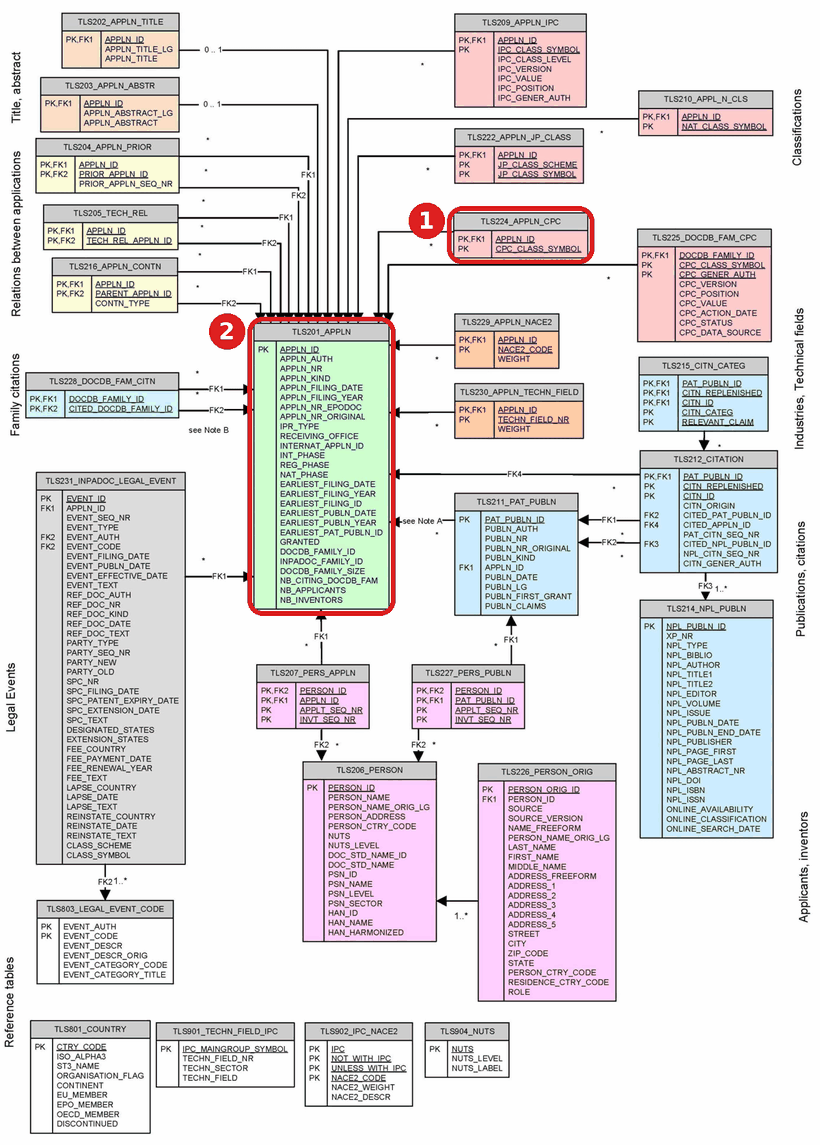

Remember `distinct`: an application with several fuel-cell symbols has several rows in TLS224.
</details>

In [36]:
# Your turn 2: fuel-cell families by priority year
symbol_no_blanks = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")

q = (
    db.query(
        TLS201_APPLN.earliest_filing_year,
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families"),
    )
    .select_from(TLS224_APPLN_CPC)                                            # 1. the CPC table
    .join(TLS201_APPLN, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)   # 2. the applications
    .filter(symbol_no_blanks.like("H01M8/%"))
    .filter(TLS201_APPLN.earliest_filing_year >= 2010)
    .group_by(TLS201_APPLN.earliest_filing_year)
    .order_by(TLS201_APPLN.earliest_filing_year)
)

patstat.df(q)

,earliest_filing_year,families
0,2010,20
1,2011,29
2,2012,11
3,2013,22
4,2014,14
5,2015,15
6,2016,27
7,2017,35
8,2018,29
9,2019,36


## 5. `TLS202_APPLN_TITLE` and `TLS203_APPLN_ABSTR`: title and abstract

These are the two text fields we use in Step 0 for keyword or semantic searches. Each has one row per application and two attributes: the text and its language.

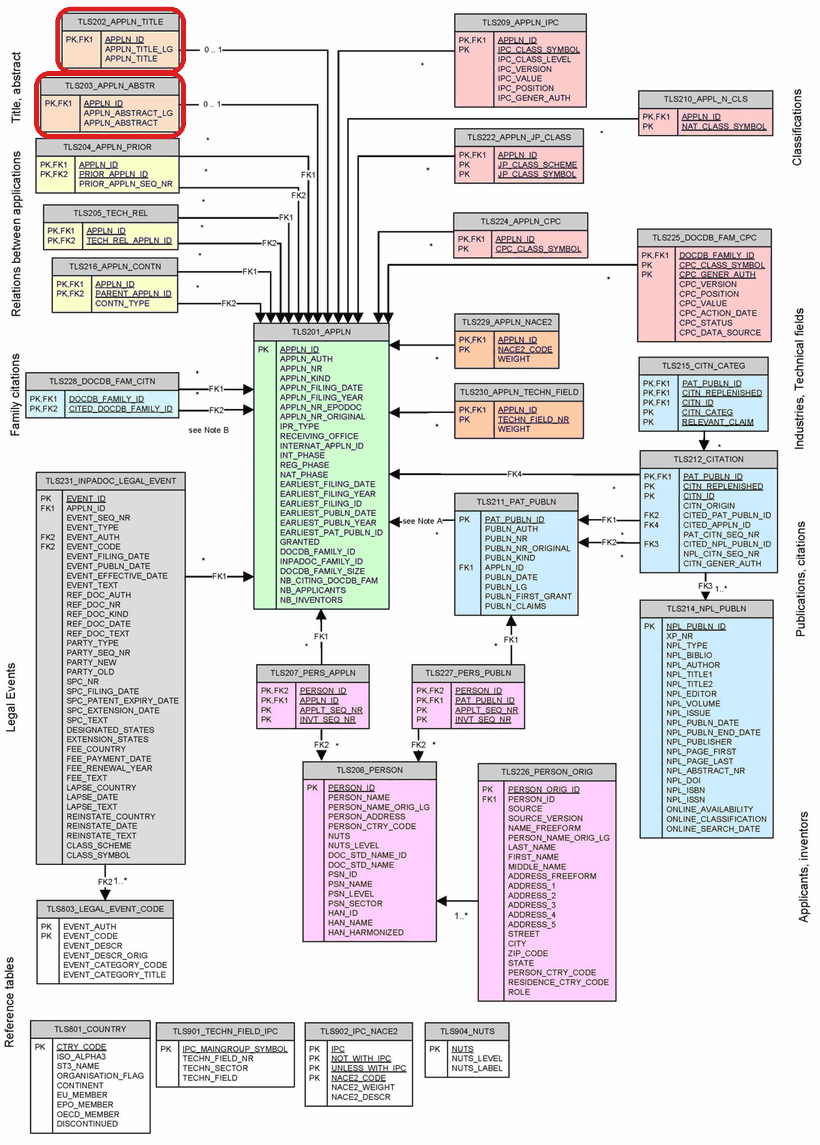

*TLS202_APPLN_TITLE and TLS203_APPLN_ABSTR: zero or one row for each application of TLS201.*

| Attribute | Meaning |
|---|---|
| `appln_title_lg`, `appln_title` | Language and text of the title. An application may have several titles (one per language), but **only one** is stored. English is preferred. |
| `appln_abstract_lg`, `appln_abstract` | Language and text of the abstract. Only one is stored, chosen with the first rule that applies: (1) the most recent abstract in English; (2) the most recent in the language of publication; (3) the most recent in any other language. |

Not every application has a title or an abstract in PATSTAT. Let's start with the languages.

In [37]:
q = (
    db.query(
        TLS202_APPLN_TITLE.appln_title_lg,
        func.count(TLS202_APPLN_TITLE.appln_id).label("applications"),
    )
    .group_by(TLS202_APPLN_TITLE.appln_title_lg)
    .order_by(func.count(TLS202_APPLN_TITLE.appln_id).desc())
    .limit(10)
)
title_lg = patstat.df(q)

q = (
    db.query(
        TLS203_APPLN_ABSTR.appln_abstract_lg,
        func.count(TLS203_APPLN_ABSTR.appln_id).label("applications"),
    )
    .group_by(TLS203_APPLN_ABSTR.appln_abstract_lg)
    .order_by(func.count(TLS203_APPLN_ABSTR.appln_id).desc())
    .limit(10)
)
abstract_lg = patstat.df(q)

# Show the two rankings next to each other
pd.concat([title_lg, abstract_lg], axis=1, keys=["titles", "abstracts"])

titles                      abstracts             
  appln_title_lg applications appln_abstract_lg applications
0             EN       301143                en       289602
1             DE         6708                de         6635
2             ES         3065                es         2974
3             DA         2535                ko         1862
4             JA         1994                ja         1817
5             PT         1401                pt         1295
6             FR         1270                fr         1132
7             KO          811                zh          684
8             RU          584                ru          376
9             ZH          569                tr          163

English dominates both tables, but not entirely: a part of the titles and abstracts is in Korean, German, Chinese, Japanese, Spanish, French... An English keyword search silently misses these applications.

How large is the gap at each office? The next query counts, for the IP5 offices, the applications that have an English title, any title, and no title at all.

In [38]:
q = (
    db.query(
        TLS201_APPLN.appln_auth,
        func.count(TLS201_APPLN.appln_id).label("applications"),
        func.count(TLS202_APPLN_TITLE.appln_id).label("with_title"),
        func.sum(case((TLS202_APPLN_TITLE.appln_title_lg == "en", 1), else_=0)).label("with_english_title"),
    )
    .outerjoin(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS201_APPLN.appln_id)  # keep applications without title
    .filter(TLS201_APPLN.appln_auth.in_(IP5))
    .filter(TLS201_APPLN.appln_filing_year.between(2015, 2020))
    .group_by(TLS201_APPLN.appln_auth)
)

titles = patstat.df(q)
titles["share_english"] = (titles["with_english_title"] / titles["applications"]).round(3)
titles

,appln_auth,applications,with_title,with_english_title,share_english
0,US,20664,20631,0,0.0
1,JP,3624,3617,0,0.0
2,EP,7803,7800,0,0.0
3,CN,78212,78211,0,0.0
4,KR,3629,3629,0,0.0


We used an **outer join**, so that applications without a title are kept (their title columns are empty) and the denominator is right. The share of applications with an English title varies by office.

Unlike CPC symbols, titles and abstracts are not shared by the family: each application keeps its own. A family usually has at least one member with an English title or abstract (often the EP, WO or US application). In Step 0, a keyword search at **family** level ("at least one application of the family matches") recovers many of the inventions first filed in other languages.

A few English abstracts, to see what the text looks like:

In [39]:
q = (
    db.query(
        TLS203_APPLN_ABSTR.appln_id,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
    )
    .join(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en")
    .limit(5)
)

patstat.df(q)

,appln_id,appln_title,appln_abstract
0,525545474,Charging device for electric vehicles,"A charging device for electric vehicles, with multiple charging points, to e..."
1,522238393,Hydroelectric system in a plant,"A combined pump and turbine (electromechanical converter), which may be oper..."
2,478342775,Device and snorkel air intake comprising device,A device for fitting to a vehicular snorkel air intake is provided. The devi...
3,52243447,Glass-ceramic composition for recording disk substrate,"A glass ceramics composition for recording disk substrate contains, essentia..."
4,329498255,Plastic welding using fiber reinforcement materials,A method of reinforcing a thermoplastic part includes softening a portion of...


Titles are short and generic ("Method and device for..."); abstracts carry most of the technical vocabulary. Some abstracts are machine translations or summaries written by the office (Japanese abstracts in English often start with `PURPOSE:`), which affects keyword matching.

## 6. `TLS207_PERS_APPLN`: who did what on which application

`TLS207` links persons (`TLS206`) to applications (`TLS201`). One row is one person on one application, with a role.

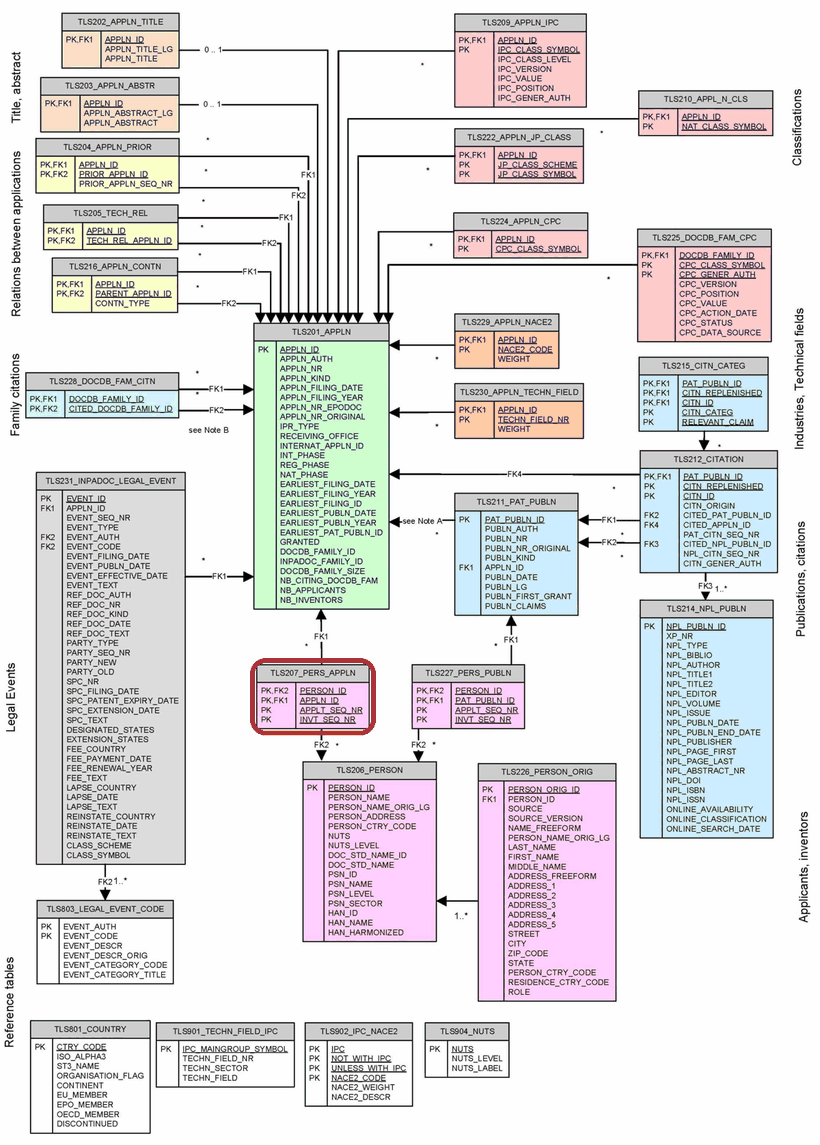

*TLS207_PERS_APPLN: the bridge between applications (TLS201) and persons (TLS206).*

| Attribute | Meaning |
|---|---|
| `person_id` | The person (key of `TLS206`). |
| `appln_id` | The application (key of `TLS201`). |
| `applt_seq_nr` | Position of the person in the list of **applicants**. 0 if the person is not an applicant. |
| `invt_seq_nr` | Position of the person in the list of **inventors**. 0 if the person is not an inventor. |

The four columns together are the primary key. A person can be both applicant and inventor (both numbers above 0): common for individual inventors, and in US applications filed before 2012, when inventors had to be applicants.

- **Applicant**: who owns the application, usually a company or a university. Used for "who is patenting?".
- **Inventor**: the people who made the invention. Used for "where is the research done?".

Let's count applicants and inventors per application.

### APPUNTI

2 purposes:
count how many iverntor a certaint patent has
how many sector a certain filing belongs to


tls206 is a dirty table. huge problem in entity linking, which is the issue that consists in a single company (applicant) appearing in a lot of patent data with different names.
example:
You check and see Nokia has 200 patents. correct? No. actually nokia has 30 different names, so you must pay attention to that.
you must calculate the concentrate of a certain sector, meaning how many applicants a certain field has. is the inventivity of a tech. sector concentrated in many or few applicants?

so if I don't do entity linking correctly, I might asssume that a sector is very concentrated while there is only one entity!!!

In [ ]:
is_applicant = TLS207_PERS_APPLN.applt_seq_nr > 0
is_inventor = TLS207_PERS_APPLN.invt_seq_nr > 0

q = (
    db.query(
        TLS207_PERS_APPLN.appln_id,
        func.count(case((is_applicant, 1))).label("n_applicants"),   # case without else -> NULL, not counted
        func.count(case((is_inventor, 1))).label("n_inventors"),
    )
    .join(TLS201_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.appln_filing_year.between(2015, 2020))
    .group_by(TLS207_PERS_APPLN.appln_id)
)

per_appln = patstat.df(q)
per_appln[["n_applicants", "n_inventors"]].describe().round(2)

Each EP application has, typically, one applicant and a few inventors. The share of applications with more than one applicant is a simple indicator of **co-applications**:

In [ ]:
print("share of applications with 2+ applicants:", round((per_appln["n_applicants"] > 1).mean(), 3))

Now the roles, counted on rows of `TLS207`:

In [ ]:
role = case(
    ((TLS207_PERS_APPLN.applt_seq_nr > 0) & (TLS207_PERS_APPLN.invt_seq_nr > 0), "applicant and inventor"),
    (TLS207_PERS_APPLN.applt_seq_nr > 0, "applicant only"),
    (TLS207_PERS_APPLN.invt_seq_nr > 0, "inventor only"),
    else_="neither",
)

q = (
    db.query(
        role.label("role"),
        func.count().label("person_application_links"),
    )
    .group_by(role)
)

patstat.df(q)

Most links are "inventor only", because an application usually has more inventors than applicants. The rows with both roles are mostly individual inventors who file their own patents.

**For Step 1:** to count applicants of your sector, filter `applt_seq_nr > 0`; for inventors, `invt_seq_nr > 0`. Never count all rows of `TLS207`: you would mix the two roles.

## 7. `TLS206_PERSON`: applicants and inventors

One row per person **as written in a filing**. The same company appears with many `person_id`s, one for each spelling of its name ("General Electric Company", "GENERAL ELECTRIC CO.", ...). Several attributes try to put the spellings together.

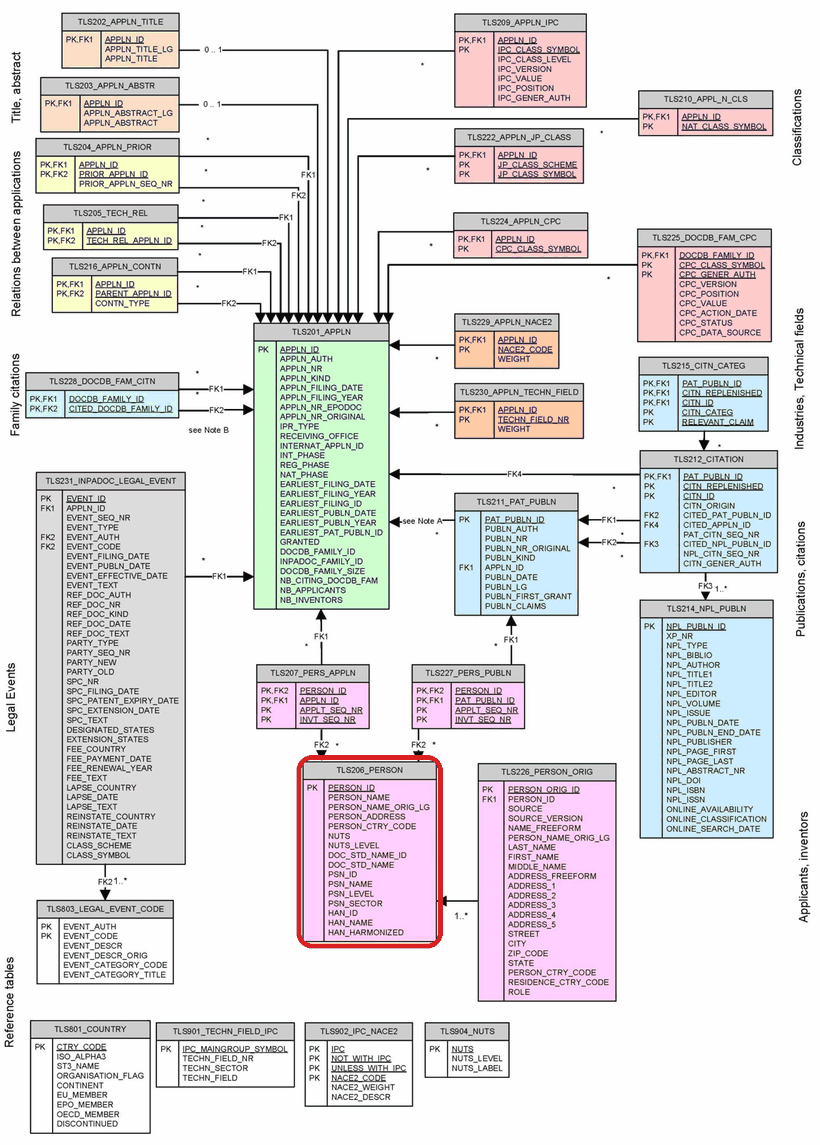

*TLS206_PERSON: reached from TLS201 only through TLS207.*

### 7.1 Names and standardised names

| Attribute | Meaning |
|---|---|
| `person_name` | The name as delivered by the office, in Latin characters. |
| `person_name_orig_lg` | The name in the original language and script (for example Chinese), when available. |
| `doc_std_name_id`, `doc_std_name` | **DOCDB standardised name**, created by the EPO. |
| `psn_id`, `psn_name` | **PATSTAT standardised name** (PSN), created for PATSTAT, partly by hand for the largest applicants. |
| `psn_level` | How much work went into the PSN name: 0 = only capitalisation and spaces cleaned, 1 = automatic cleaning, 2 = checked by a person. It describes the quality of `psn_name`, nothing else. |
| `han_id`, `han_name` | **Harmonised applicant name** (HAN) from the OECD. |
| `han_harmonized` | 0 = not harmonised (the original name is copied), 1 = harmonised, 2 = harmonised and matched with the ORBIS company database. |

See how the spellings of General Electric are grouped by HAN:

columns of armonized names. there are 2, han_id and han_name. both  of these are badly done since they only cluster very similar names. we are going to miss many. 
example:
nokia has name NokiaCorporation, but also Nokian. not so trivial, we can't just match words.

so what? maybe a proxy of patent location could work, but there is no exact match between where the r&d is made and in which office the patent is filed. 
so which is a better proxy?
ADDRESS AND COUTNRY OF THE INVENTOR. you can see below.

In [ ]:
q = (
    db.query(
        TLS206_PERSON.person_name,
        TLS206_PERSON.doc_std_name,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.psn_level,
        TLS206_PERSON.han_name,
        TLS206_PERSON.han_harmonized,
    )
    .filter(TLS206_PERSON.han_name == "GENERAL ELECT CO")
    .distinct()
    .limit(15)
)

patstat.df(q)

Different `person_name`s ("GENERAL ELECTRIC COMPANY", "General Electric Co.", even the misspelt "General Electronic Company") share one `han_name`. The three standardisations do not always agree with each other.

**For Step 1 (and Step 2):** count applicants on `psn_name` or `han_name`, never on `person_name`, otherwise one company becomes many. None of them merges subsidiaries into their group: that is a consolidation step we do in Step 2.

### 7.2 `person_ctry_code` and `person_address`

`person_ctry_code` is the country of residence of the person, as a two-letter code. When it is missing, it is **two blanks** (`'  '`), not NULL. `person_address` is the address, often missing.

This is the attribute behind "where does the invention come from?" (inventor countries) and "who owns it?" (applicant countries). How complete is it? Let's compute the share of applicant and inventor links with a missing country, by filing office.

In [ ]:
missing_ctry = TLS206_PERSON.person_ctry_code == "  "   # two blanks = missing

q = (
    db.query(
        TLS201_APPLN.appln_auth,
        func.count().label("person_links"),
        func.sum(case((missing_ctry, 1), else_=0)).label("missing_country"),
        func.sum(case((TLS206_PERSON.person_address.is_(None), 1), else_=0)).label("missing_address"),
    )
    .select_from(TLS207_PERS_APPLN)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .join(TLS201_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS201_APPLN.appln_auth.in_(IP5 + ["WO"]))
    .group_by(TLS201_APPLN.appln_auth)
)

ctry = patstat.df(q)
ctry["share_missing_country"] = (ctry["missing_country"] / ctry["person_links"]).round(3)
ctry["share_missing_address"] = (ctry["missing_address"] / ctry["person_links"]).round(3)
ctry.sort_values("share_missing_country", ascending=False)

For some offices (JP and CN in particular) the country is missing for almost every person, while it is nearly complete at EP and WO. The address is missing even more often.

**For Step 1:** do not compute applicant or inventor countries on all applications of a family taken at random. For each family, take the country from the applications where it is available (typically EP, WO, US), as we did in Tutorial 0. Otherwise China and Japan disappear from your geography.

### APPUNTI

30% has sector: unknown

remember to keep this into account. NEVER show in your data this, we must solve and somehow manage to identify this 30% or handle it differently
for example we can use extenstions, or train a simple multiclass classifier from data online.


### 7.3 `psn_sector`: what kind of applicant

`psn_sector` classifies the PSN name into sectors: `COMPANY`, `UNIVERSITY`, `GOV NON-PROFIT`, `INDIVIDUAL`, `HOSPITAL`, `UNKNOWN`, combinations such as `COMPANY GOV NON-PROFIT`, or empty.

In [ ]:
q = (
    db.query(
        TLS206_PERSON.psn_sector,
        func.count(TLS207_PERS_APPLN.appln_id.distinct()).label("applications"),
    )
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .join(TLS201_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)              # applicants only
    .filter(TLS201_APPLN.appln_auth == "EP")
    .group_by(TLS206_PERSON.psn_sector)
    .order_by(func.count(TLS207_PERS_APPLN.appln_id.distinct()).desc())
)

patstat.df(q)

The table counts EP applications by the sector of their applicants. Companies are the large majority; universities and public research organisations follow. An application with a company and a university is counted in both rows.

**For Step 1:** the share of universities and public bodies says whether your sector is still close to science or already in the hands of industry. Look at the `UNKNOWN` and empty rows: if they are large in your sector, the shares of the other sectors are underestimated.

### 7.4 NUTS regions

For European persons, `nuts` gives the region (Nomenclature of Territorial Units for Statistics) and `nuts_level` its precision:

| `nuts_level` | Meaning |
|---|---|
| 0 | country only (not an official NUTS level) |
| 1, 2, 3 | official NUTS levels, from large regions to provinces |
| 4 | NUTS 3 provided by the OECD REGPAT database |
| 9 | no NUTS code |

In [ ]:
q = (
    db.query(
        TLS206_PERSON.nuts_level,
        func.count(TLS206_PERSON.person_id).label("persons"),
    )
    .group_by(TLS206_PERSON.nuts_level)
    .order_by(TLS206_PERSON.nuts_level)
)

patstat.df(q)

Most persons have no NUTS code (level 9): the field is empty outside Europe and often inside it. Use it only for a regional focus on Europe, and only for the persons with level 3 or 4.

### 7.5 Putting it together: top applicants

To close, the main applicants of EP applications in a period, counted in DOCDB families and grouped on `psn_name`, with their country and sector.

In [ ]:
q = (
    db.query(
        TLS206_PERSON.psn_name,
        TLS206_PERSON.person_ctry_code,
        TLS206_PERSON.psn_sector,
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families"),
    )
    .select_from(TLS207_PERS_APPLN)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .join(TLS201_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)               # applicants only
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.earliest_filing_year.between(2015, 2020))
    .group_by(TLS206_PERSON.psn_name, TLS206_PERSON.person_ctry_code, TLS206_PERSON.psn_sector)
    .order_by(func.count(TLS201_APPLN.docdb_family_id.distinct()).desc())
    .limit(15)
)

patstat.df(q)

The query uses all the pieces of this notebook: `TLS207` with `applt_seq_nr > 0` to keep applicants, `TLS206.psn_name` to merge spellings, `TLS201` for the office and the priority year, and distinct `docdb_family_id` to count inventions. A company can still appear twice if its persons have different country codes; this is one of the issues we deal with in Step 2.

## 8. Your turn: which tables, and in which order?

### Your turn 3 · How many inventions are owned by Chinese applicants?

**Question:** how many families with priority year 2015 have **at least one Chinese applicant**?

Compare it with Your turn 1. Which tables do you need now, and in which order?

<details>
<summary><b>Solution</b> (click to open)</summary>

Now "China" is the **country of the applicant**, not the office. The country is an attribute of the person, so we need three tables:

1. **TLS201_APPLN**: the applications, with `earliest_filing_year` and `docdb_family_id`.
2. **TLS207_PERS_APPLN**: join on `appln_id`, keep the applicants (`applt_seq_nr > 0`).
3. **TLS206_PERSON**: join on `person_id`, keep `person_ctry_code = 'CN'`.

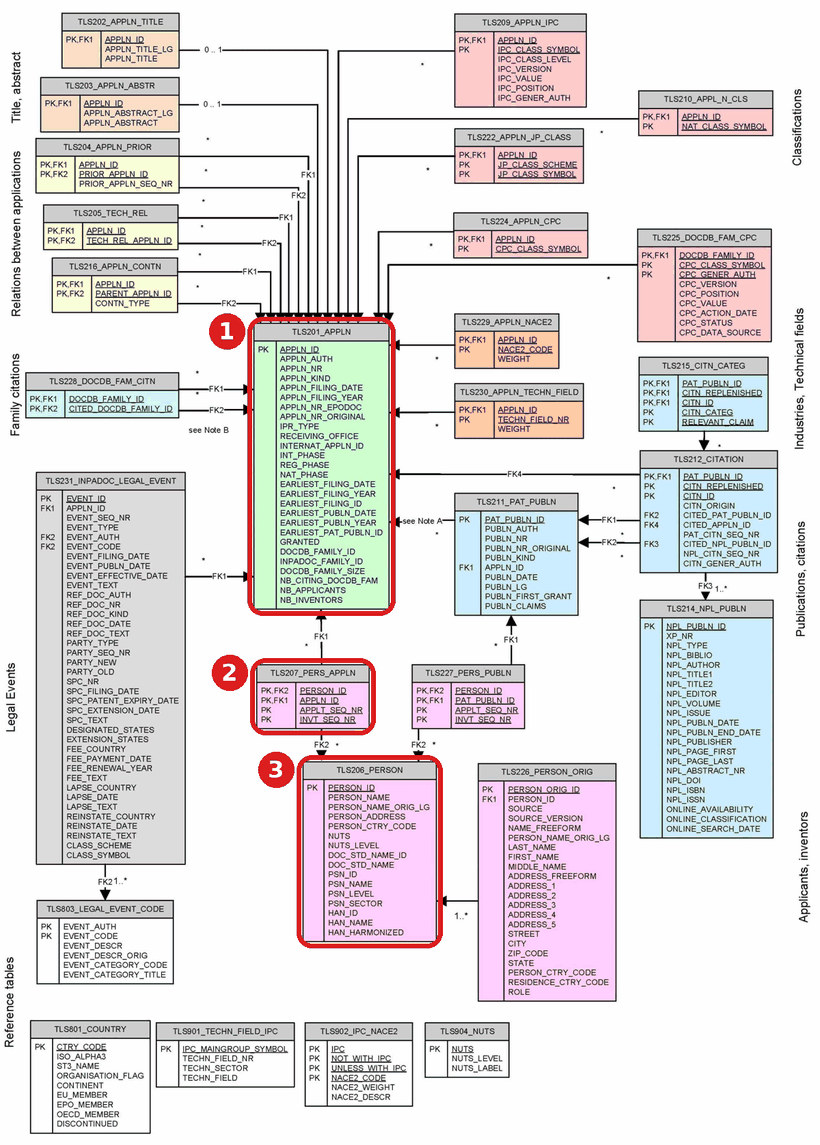

Two traps: a family has several applicants, so count `docdb_family_id` with `distinct`; and the country is often missing for applications filed at the Chinese office (section 7.2), so this count is a lower bound.
</details>

In [ ]:
# Your turn 3: families of 2015 with at least one applicant from China
q = (
    db.query(
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families_with_chinese_applicant"),
    )
    .select_from(TLS201_APPLN)                                                    # 1. applications
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)  # 2. links
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)   # 3. persons
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)          # applicants only
    .filter(TLS206_PERSON.person_ctry_code == "CN")      # from China
    .filter(TLS201_APPLN.earliest_filing_year == 2015)
    .filter(TLS201_APPLN.appln_id < 900000000)
)

patstat.df(q)

"Filed in China" (Your turn 1) and "owned by Chinese applicants" (Your turn 3) are different questions, with different tables and different numbers. In Step 1 always say which one you are measuring.

### Your turn 4 · Which universities work on fuel cells?

**Question:** which universities have the most fuel-cell inventions (CPC `H01M 8/`)?

Which tables do you need, and in which order?

<details>
<summary><b>Solution</b> (click to open)</summary>

Four tables, from the technology to the applicant:

1. **TLS224_APPLN_CPC**: the fuel-cell applications.
2. **TLS201_APPLN**: join on `appln_id`, to count families with `docdb_family_id`.
3. **TLS207_PERS_APPLN**: join on `appln_id`, keep the applicants.
4. **TLS206_PERSON**: join on `person_id`, keep `psn_sector = 'UNIVERSITY'` and group by `psn_name`.

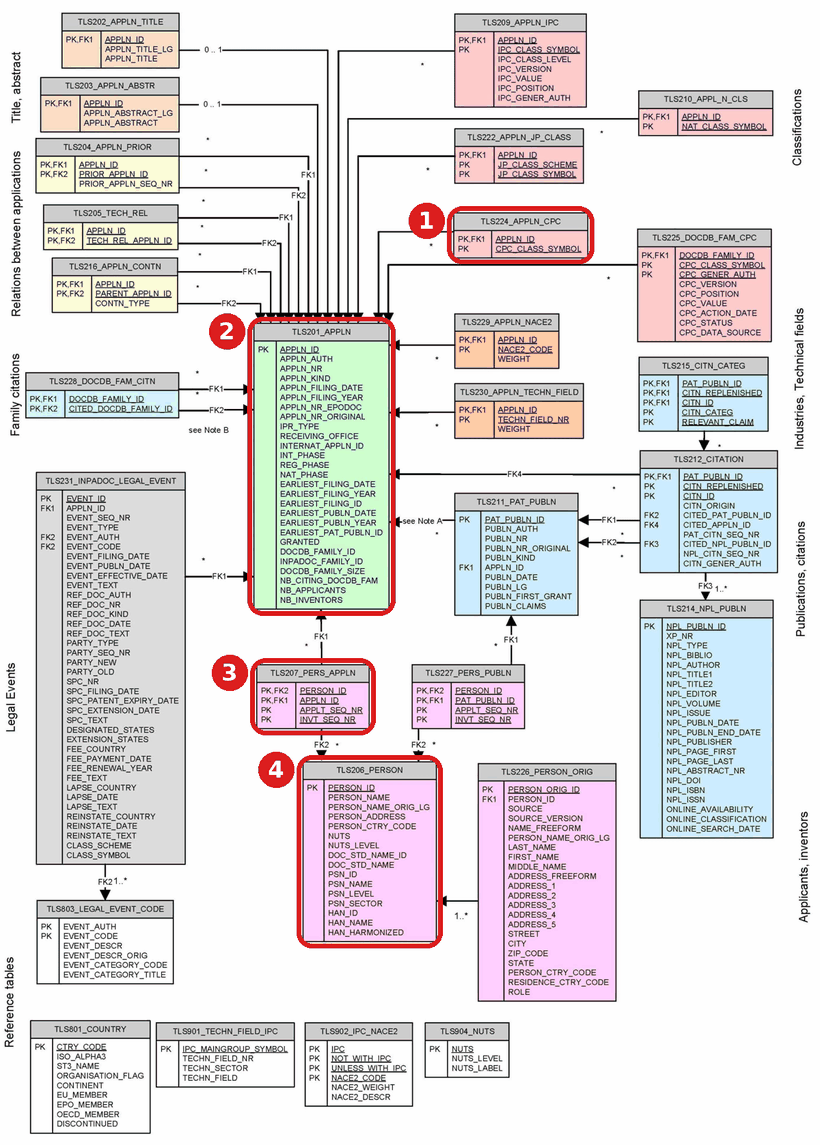
</details>

In [ ]:
# Your turn 4: top universities in fuel cells, counted in families
symbol_no_blanks = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")

q = (
    db.query(
        TLS206_PERSON.psn_name,
        func.count(TLS201_APPLN.docdb_family_id.distinct()).label("families"),
    )
    .select_from(TLS224_APPLN_CPC)                                                 # 1. CPC
    .join(TLS201_APPLN, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)        # 2. applications
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)  # 3. links
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)   # 4. persons
    .filter(symbol_no_blanks.like("H01M8/%"))
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)          # applicants only
    .filter(TLS206_PERSON.psn_sector == "UNIVERSITY")
    .group_by(TLS206_PERSON.psn_name)
    .order_by(func.count(TLS201_APPLN.docdb_family_id.distinct()).desc())
    .limit(10)
)

patstat.df(q)

---

← [Tutorial 0 · Step 1 of the PW: general description of the sector](../tutorial_0/02_step1_general_description.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)